# Automata Theory in Today's World: Real-Life Automation at Scale

**Goal:** show how the classic machines of automata theory (DFA, NFA, Mealy/Moore, pushdown automata, Turing machines, probabilistic automata) run inside modern automation systems, using **millions of simulated events** instead of toy examples.

| # | Automaton | Real-life automation system simulated here | Data scale |
|---|-----------|--------------------------------------------|-----------|
| 1 | DFA + Mealy/Moore | Smart-factory machine supervisor (Industry 4.0 / IoT) | 2,000 machines × 1,000 events = **2 M events** |
| 2 | NFA → DFA (subset construction) | Pattern detection in sensor event streams | 2 M events + exponential blow-up study |
| 3 | Regular languages / regex engines | Log parsing & ReDoS (why DFA engines matter) | **1 M log lines** |
| 4 | DFA minimisation | Shrinking a redundant controller | state-space reduction |
| 5 | Pushdown automaton | Validating nested workflow / config blocks | **100 k programs (~3 M tokens)** |
| 6 | Turing machine | Production-line count verification (aⁿbⁿcⁿ) | 3,000 inputs + complexity scaling |
| 7 | Probabilistic automaton (Markov chain) | Predictive maintenance | learned from 2 M transitions |
| 8 | DFA as business-process monitor | E-commerce order fulfilment / RPA | **1 M orders × 12 steps** |

**Why it matters today:** PLC/SCADA controllers, IoT device lifecycles, CI/CD pipelines, API gateways, network protocols (TCP, TLS, MQTT), regex-based security filters (WAF/IDS), smart contracts, autonomous-vehicle behaviour planners and guardrails for AI-agent workflows are all finite-state or pushdown machines under the hood.

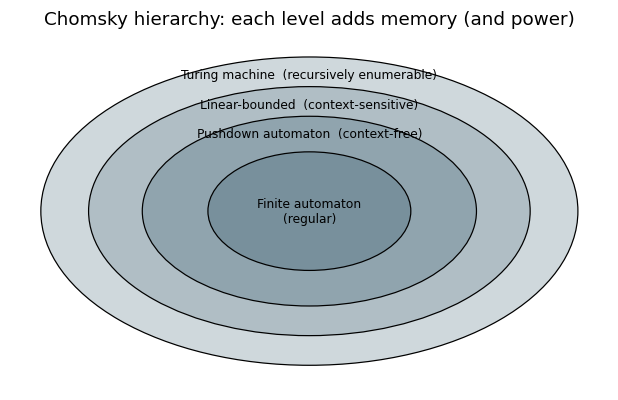

In [1]:
import time, re, math, random, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from matplotlib.patches import Ellipse
from IPython.display import display

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})
rng = np.random.default_rng(42)
random.seed(42)
results = {}          # scorecard filled throughout the notebook

# ---- Chomsky hierarchy picture ----
fig, ax = plt.subplots(figsize=(7, 4.2))
layers = [("Turing machine  (recursively enumerable)", 9.0, 5.2, "#cfd8dc", 2.3),
          ("Linear-bounded  (context-sensitive)",       7.4, 4.2, "#b0bec5", 1.8),
          ("Pushdown automaton  (context-free)",        5.6, 3.2, "#90a4ae", 1.3),
          ("Finite automaton\n(regular)",               3.4, 2.0, "#78909c", 0.0)]
for name, w, h, c, ty in layers:
    ax.add_patch(Ellipse((0, 0), w, h, fc=c, ec="k", lw=.8))
    ax.text(0, ty, name, ha="center", va="center", fontsize=8)
ax.set_xlim(-5, 5); ax.set_ylim(-3, 3); ax.axis("off")
ax.set_title("Chomsky hierarchy: each level adds memory (and power)")
plt.show()

## 1. Deterministic Finite Automaton (DFA): the machine supervisor

A DFA is a 5-tuple **M = (Q, Σ, δ, q₀, F)**. In a smart factory every machine obeys a *life-cycle protocol*: you cannot `start` a machine that is in `FAULT`, nor `repair` one that is `RUNNING`. A DFA encodes this protocol, and any event with **no transition is a protocol violation** (a bug, a bad operator command, or a cyber-attack).

We implement a reusable `DFA` class, then run it over **2,000 machines × 1,000 events**.

In [2]:
class DFA:
    # Deterministic finite automaton (Q, Sigma, delta, q0, F)
    def __init__(self, states, alphabet, delta, start, accepting):
        self.states, self.alphabet = list(states), list(alphabet)
        self.delta, self.start, self.accepting = dict(delta), start, set(accepting)
        self.s_idx = {s: i for i, s in enumerate(self.states)}
        self.a_idx = {a: i for i, a in enumerate(self.alphabet)}
    def step(self, q, a):
        return self.delta.get((q, a))            # None -> no transition (violation)
    def run(self, word):
        q = self.start
        for a in word:
            q = self.step(q, a)
            if q is None: return None
        return q
    def accepts(self, word):
        return self.run(word) in self.accepting
    def table(self):
        # numpy transition table; missing transitions point to an extra DEAD state
        dead = len(self.states)
        T = np.full((dead + 1, len(self.alphabet)), dead, dtype=np.int16)
        for (q, a), r in self.delta.items():
            T[self.s_idx[q], self.a_idx[a]] = self.s_idx[r]
        return T, dead

STATES = ["OFF", "IDLE", "RUNNING", "FAULT", "MAINT"]
EVENTS = ["power_on", "start", "stop", "error", "repair", "service", "power_off"]
S = {s: i for i, s in enumerate(STATES)}
E = {e: i for i, e in enumerate(EVENTS)}

delta = {("OFF", "power_on"): "IDLE",
         ("IDLE", "start"): "RUNNING", ("IDLE", "service"): "MAINT", ("IDLE", "power_off"): "OFF",
         ("RUNNING", "stop"): "IDLE", ("RUNNING", "error"): "FAULT",
         ("FAULT", "repair"): "IDLE", ("FAULT", "service"): "MAINT", ("FAULT", "power_off"): "OFF",
         ("MAINT", "repair"): "IDLE", ("MAINT", "power_off"): "OFF"}
machine = DFA(STATES, EVENTS, delta, start="IDLE", accepting={"IDLE", "OFF"})

print("legal run   :", machine.run(["start", "error", "repair", "start", "stop"]))
print("illegal run :", machine.run(["start", "error", "start"]), "<- 'start' while FAULT has no transition")
print("accepts clean shutdown?", machine.accepts(["start", "stop", "power_off"]))
Tab, DEAD = machine.table()
display(pd.DataFrame(Tab[:-1], index=STATES, columns=EVENTS).replace(DEAD, "-").replace({i: s for i, s in enumerate(STATES)}))

legal run   : IDLE
illegal run : None <- 'start' while FAULT has no transition
accepts clean shutdown? True


,power_on,start,stop,error,repair,service,power_off
OFF,IDLE,-,-,-,-,-,-
IDLE,-,RUNNING,-,-,-,MAINT,OFF
RUNNING,-,-,IDLE,FAULT,-,-,-
FAULT,-,-,-,-,IDLE,MAINT,OFF
MAINT,-,-,-,-,IDLE,-,OFF


### Generating 2 M realistic events
Each machine emits events according to what is *plausible* in its current state (weights below), plus **3 % random noise** (glitches / spoofed commands). 10 % of machines are secretly **faulty** (5× error rate). The supervisor DFA does not know that, so we'll see whether the automaton-derived statistics reveal it.

In [3]:
M, T = 2000, 1000
Wbase = np.zeros((5, 7))
Wbase[S["OFF"],     E["power_on"]] = 1.0
Wbase[S["IDLE"],    [E["start"], E["service"], E["power_off"]]] = [.70, .08, .10]
Wbase[S["RUNNING"], [E["stop"], E["error"]]] = [1.0, .03]
Wbase[S["FAULT"],   [E["repair"], E["service"], E["power_off"]]] = [.80, .12, .08]
Wbase[S["MAINT"],   [E["repair"], E["power_off"]]] = [.90, .10]

faulty = rng.random(M) < 0.10
err_scale = np.where(faulty, 5.0, 1.0)

t0 = time.time()
ev = np.empty((M, T), np.int8)
st = np.full(M, S["IDLE"])
for t in range(T):
    w = Wbase[st].copy(); w[:, E["error"]] *= err_scale
    p = w / w.sum(1, keepdims=True)
    e = np.minimum((rng.random((M, 1)) > p.cumsum(1)).sum(1), 6)
    noise = rng.random(M) < 0.03
    e = np.where(noise, rng.integers(0, 7, M), e)
    ev[:, t] = e
    nxt = Tab[st, e]; st = np.where(nxt == DEAD, st, nxt)
print(f"generated {ev.size:,} events in {time.time()-t0:.2f}s;  faulty machines: {faulty.sum()}")

# ---- run the DFA supervisor over the recorded log (vectorised over machines) ----
def monitor(ev, Tab, DEAD, start):
    M_, T_ = ev.shape
    cur = np.full(M_, start); after = np.empty((M_, T_), np.int8); viol = np.zeros((M_, T_), bool)
    for t in range(T_):
        nxt = Tab[cur, ev[:, t]]; bad = nxt == DEAD
        cur = np.where(bad, cur, nxt)
        after[:, t], viol[:, t] = cur, bad
    return after, viol

t0 = time.time()
after, viol = monitor(ev, Tab, DEAD, S["IDLE"])
before = np.concatenate([np.full((M, 1), S["IDLE"], np.int8), after[:, :-1]], axis=1)
print(f"DFA monitored {ev.size:,} events in {time.time()-t0:.2f}s")

df = pd.DataFrame({
    "machine": np.repeat(np.arange(M), T).astype(np.int32),
    "t": np.tile(np.arange(T), M).astype(np.int16),
    "event": pd.Categorical.from_codes(ev.ravel(), EVENTS),
    "state_before": pd.Categorical.from_codes(before.ravel().astype(np.int8), STATES),
    "state_after": pd.Categorical.from_codes(after.ravel().astype(np.int8), STATES),
    "violation": viol.ravel()})
print(f"event table: {len(df):,} rows, {df.memory_usage(deep=True).sum()/1e6:.0f} MB")
display(df.head(8))
results["Events processed by DFA"] = f"{len(df):,}"
results["Protocol violations flagged"] = f"{viol.sum():,} ({viol.mean():.2%})"

generated 2,000,000 events in 0.41s;  faulty machines: 186
DFA monitored 2,000,000 events in 0.03s
event table: 2,000,000 rows, 20 MB


,machine,t,event,state_before,state_after,violation
0,0,0,service,IDLE,MAINT,False
1,0,1,repair,MAINT,IDLE,False
2,0,2,start,IDLE,RUNNING,False
3,0,3,stop,RUNNING,IDLE,False
4,0,4,start,IDLE,RUNNING,False
5,0,5,stop,RUNNING,IDLE,False
6,0,6,start,IDLE,RUNNING,False
7,0,7,stop,RUNNING,IDLE,False


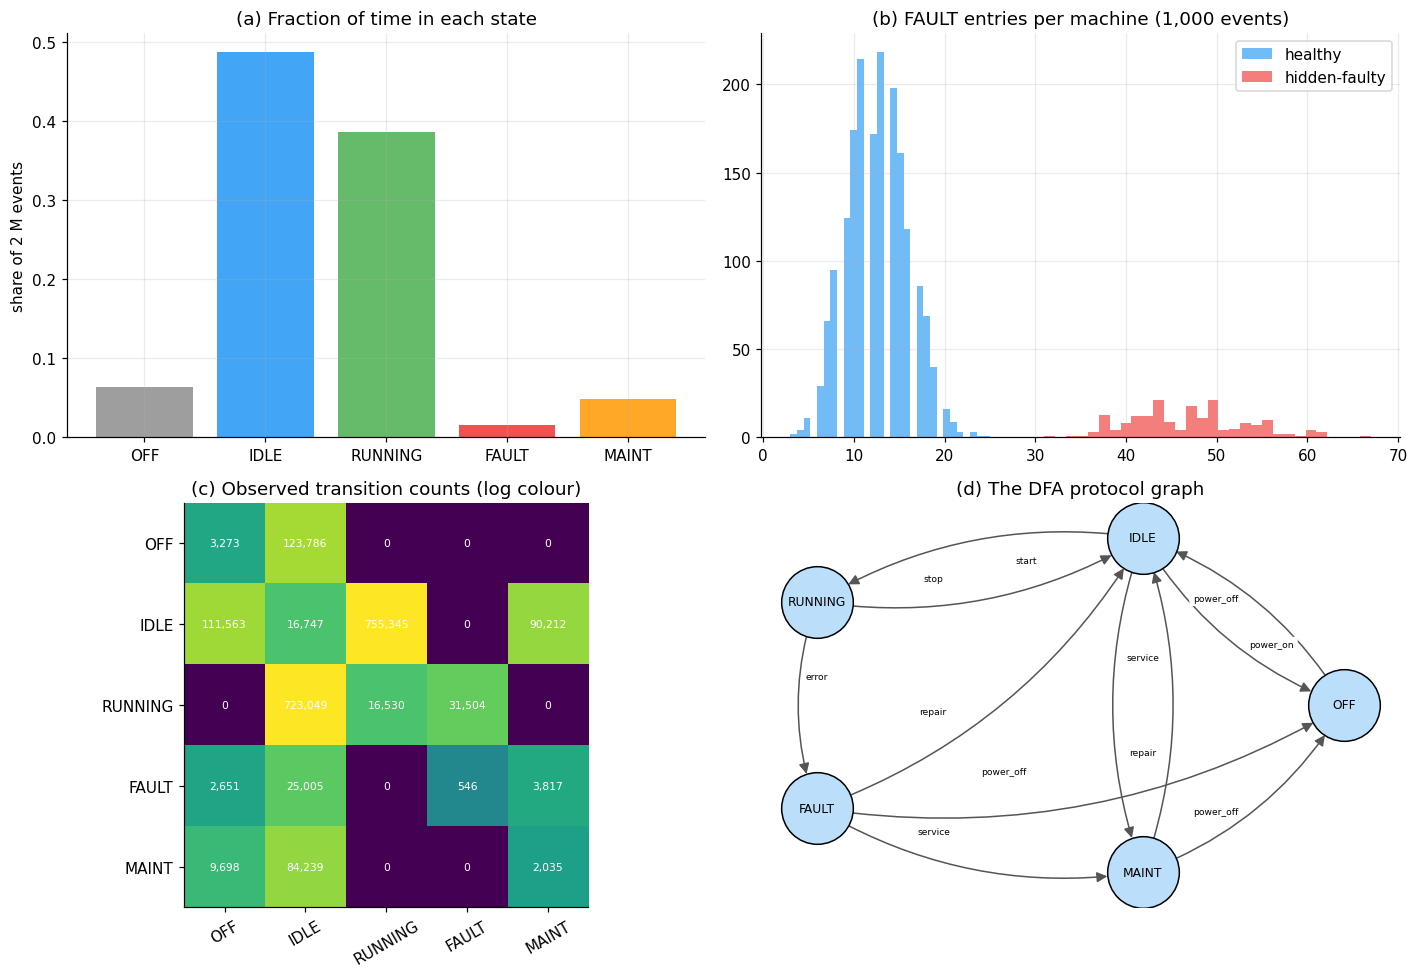

mean FAULT entries: healthy=12.6  faulty=46.7


In [4]:
fault_entries = ((after == S["FAULT"]) & (before != S["FAULT"])).sum(1)
cnt = np.bincount((before.astype(int) * 5 + after).ravel(), minlength=25).reshape(5, 5)

fig, axs = plt.subplots(2, 2, figsize=(13, 9))
# (a) occupancy
occ = np.bincount(after.ravel(), minlength=5) / after.size
axs[0, 0].bar(STATES, occ, color=["#9e9e9e", "#42a5f5", "#66bb6a", "#ef5350", "#ffa726"])
axs[0, 0].set_title("(a) Fraction of time in each state"); axs[0, 0].set_ylabel("share of 2 M events")
# (b) fault entries
axs[0, 1].hist(fault_entries[~faulty], bins=30, alpha=.75, label="healthy", color="#42a5f5")
axs[0, 1].hist(fault_entries[faulty], bins=30, alpha=.75, label="hidden-faulty", color="#ef5350")
axs[0, 1].set_title("(b) FAULT entries per machine (1,000 events)"); axs[0, 1].legend()
# (c) heatmap
im = axs[1, 0].imshow(np.log10(cnt + 1), cmap="viridis")
axs[1, 0].set_xticks(range(5)); axs[1, 0].set_xticklabels(STATES, rotation=30)
axs[1, 0].set_yticks(range(5)); axs[1, 0].set_yticklabels(STATES); axs[1, 0].grid(False)
for i in range(5):
    for j in range(5):
        axs[1, 0].text(j, i, f"{cnt[i,j]:,}", ha="center", va="center", color="w", fontsize=7)
axs[1, 0].set_title("(c) Observed transition counts (log colour)")
# (d) state diagram
G = nx.DiGraph(); G.add_nodes_from(STATES)
for (q, a), r in delta.items(): G.add_edge(q, r, label=a)
pos = nx.circular_layout(G)
nx.draw_networkx_nodes(G, pos, node_color="#bbdefb", node_size=2200, ax=axs[1, 1], edgecolors="k")
nx.draw_networkx_labels(G, pos, font_size=8, ax=axs[1, 1])
nx.draw_networkx_edges(G, pos, ax=axs[1, 1], arrows=True, arrowsize=14, node_size=2200,
                       connectionstyle="arc3,rad=0.18", edge_color="#555")
nx.draw_networkx_edge_labels(G, pos, nx.get_edge_attributes(G, "label"), ax=axs[1, 1],
                             font_size=6, label_pos=.35, rotate=False)
axs[1, 1].set_title("(d) The DFA protocol graph"); axs[1, 1].axis("off")
plt.tight_layout(); plt.show()
print(f"mean FAULT entries: healthy={fault_entries[~faulty].mean():.1f}  faulty={fault_entries[faulty].mean():.1f}")

### Mealy machine: turning the DFA into an *actuator*
A **Mealy machine** adds an output function **λ(state, event)**. This is exactly what a PLC does: *when* a transition happens, it fires an action (alarm, notification, reject-command).

In [5]:
def mealy_output(q_before, event, q_after, violated):
    if violated:                                  return "REJECT_COMMAND"
    if q_after == "FAULT" and q_before != "FAULT": return "RAISE_ALARM"
    if q_before == "FAULT" and q_after == "IDLE":  return "CLEAR_ALARM"
    if q_after == "MAINT":                         return "NOTIFY_TECHNICIAN"
    return "-"

sample = df[df.machine == int(np.argmax(fault_entries))].head(40)
out = [mealy_output(a, e, b, v) for a, e, b, v in zip(sample.state_before, sample.event, sample.state_after, sample.violation)]
sample = sample.assign(output=out)
display(sample[sample.output != "-"].head(10))

# fleet-wide output counts (vectorised version of the same λ)
outs = pd.Series({"REJECT_COMMAND": int(viol.sum()),
                  "RAISE_ALARM": int(((after == S["FAULT"]) & (before != S["FAULT"]) & ~viol).sum()),
                  "CLEAR_ALARM": int(((before == S["FAULT"]) & (after == S["IDLE"]) & ~viol).sum()),
                  "NOTIFY_TECHNICIAN": int(((after == S["MAINT"]) & ~viol).sum())})
display(outs.to_frame("count"))
results["Alarms raised by Mealy machine"] = f"{outs['RAISE_ALARM']:,}"

,machine,t,event,state_before,state_after,violation,output
920011,920,11,error,RUNNING,FAULT,False,RAISE_ALARM
920012,920,12,repair,FAULT,IDLE,False,CLEAR_ALARM
920016,920,16,error,RUNNING,FAULT,False,RAISE_ALARM
920017,920,17,repair,FAULT,IDLE,False,CLEAR_ALARM
920025,920,25,error,RUNNING,FAULT,False,RAISE_ALARM
920026,920,26,service,FAULT,MAINT,False,NOTIFY_TECHNICIAN
920029,920,29,error,RUNNING,FAULT,False,RAISE_ALARM
920030,920,30,service,FAULT,MAINT,False,NOTIFY_TECHNICIAN
920037,920,37,error,RUNNING,FAULT,False,RAISE_ALARM


,count
REJECT_COMMAND,39131
RAISE_ALARM,31504
CLEAR_ALARM,25005
NOTIFY_TECHNICIAN,94029


## 2. Non-deterministic Finite Automaton (NFA) → DFA by subset construction

Detecting *patterns in event streams* is naturally expressed as an NFA ("guess" where the pattern starts). Production engines then convert it to a DFA so each event costs **O(1)**.

**Pattern (infant-mortality failure):** `repair → start → error` (a machine fails right after being repaired and restarted). The NFA below keeps looping on every symbol and *guesses* when the pattern begins.

In [6]:
class NFA:
    def __init__(self, alphabet, delta, start, accepting):
        self.alphabet, self.delta, self.start, self.accepting = list(alphabet), delta, start, set(accepting)
    def accepts(self, word):
        cur = {self.start}
        for a in word:
            nxt = set()
            for q in cur: nxt |= self.delta.get((q, a), set())
            cur = nxt
            if not cur: return False
        return bool(cur & self.accepting)
    def to_dfa(self):
        start = frozenset([self.start]); seen, queue, d = {start}, [start], {}
        while queue:
            Sset = queue.pop()
            for a in self.alphabet:
                Tset = frozenset().union(*[self.delta.get((q, a), frozenset()) for q in Sset])
                d[(Sset, a)] = Tset
                if Tset not in seen: seen.add(Tset); queue.append(Tset)
        acc = [x for x in seen if x & self.accepting]
        return DFA(list(seen), self.alphabet, d, start, acc)

nd = {(0, a): {0} for a in EVENTS}
nd[(0, "repair")] = {0, 1}; nd[(1, "start")] = {2}; nd[(2, "error")] = {3}
pattern_nfa = NFA(EVENTS, nd, 0, {3})
pattern_dfa = pattern_nfa.to_dfa()
print(f"NFA states: 4   ->   DFA states after subset construction: {len(pattern_dfa.states)}")

# --- sanity: NFA and DFA agree on 3,000 random words (ends-with-pattern language: Sigma* r s e) ---
ok = True
for _ in range(3000):
    w = [random.choice(EVENTS) for _ in range(random.randint(0, 9))]
    ok &= pattern_nfa.accepts(w) == pattern_dfa.accepts(w)
print("NFA == DFA on 3,000 random words:", ok)

# --- scan the 2 M events with the DFA (vectorised) ---
Tp, _ = pattern_dfa.table()
acc_mask = np.array([s in pattern_dfa.accepting for s in pattern_dfa.states] + [False])
cur = np.full(M, pattern_dfa.s_idx[pattern_dfa.start]); matches = np.zeros(M, int)
t0 = time.time()
for t in range(T):
    cur = Tp[cur, ev[:, t]]; matches += acc_mask[cur]
print(f"DFA scan of {ev.size:,} events: {time.time()-t0:.3f}s, total pattern matches = {matches.sum():,}")

# --- independent check with plain numpy window comparison ---
direct = ((ev[:, :-2] == E["repair"]) & (ev[:, 1:-1] == E["start"]) & (ev[:, 2:] == E["error"])).sum(1)
print("DFA matches == brute-force matches:", bool((direct == matches).all()))
print(f"matches/machine: healthy={matches[~faulty].mean():.2f}  faulty={matches[faulty].mean():.2f}")
results["Infant-mortality patterns found"] = f"{matches.sum():,}"

NFA states: 4   ->   DFA states after subset construction: 4
NFA == DFA on 3,000 random words: True
DFA scan of 2,000,000 events: 0.025s, total pattern matches = 3,960
DFA matches == brute-force matches: True
matches/machine: healthy=1.33  faulty=8.31


### The price of non-determinism: exponential state blow-up
For the language *"the k-th symbol from the end is `a`"* the NFA needs only **k+1** states, but **every** equivalent DFA needs **2ᵏ**. We measure it with real subset construction.

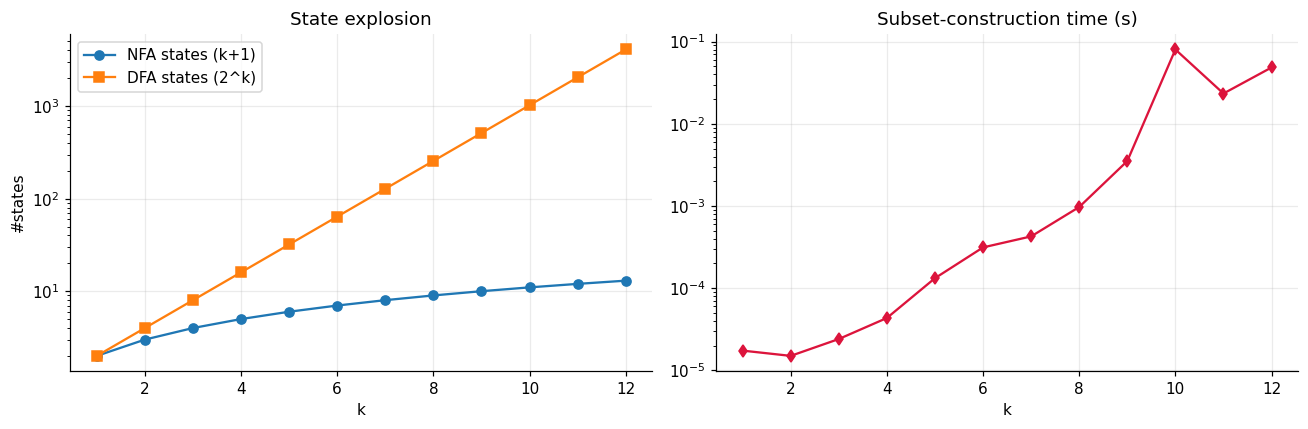

k    1  2  3   4   5   6    7    8    9    10    11    12
NFA  2  3  4   5   6   7    8    9   10    11    12    13
DFA  2  4  8  16  32  64  128  256  512  1024  2048  4096


In [7]:
def kth_from_end_nfa(k):
    d = {(0, "a"): {0, 1}, (0, "b"): {0}}
    for i in range(1, k): d[(i, "a")] = {i + 1}; d[(i, "b")] = {i + 1}
    return NFA("ab", d, 0, {k})

ks = list(range(1, 13)); nfa_sz, dfa_sz, tm = [], [], []
for k in ks:
    n = kth_from_end_nfa(k); t0 = time.time(); d = n.to_dfa()
    nfa_sz.append(k + 1); dfa_sz.append(len(d.states)); tm.append(time.time() - t0)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].semilogy(ks, nfa_sz, "o-", label="NFA states (k+1)"); ax[0].semilogy(ks, dfa_sz, "s-", label="DFA states (2^k)")
ax[0].set_xlabel("k"); ax[0].set_ylabel("#states"); ax[0].legend(); ax[0].set_title("State explosion")
ax[1].semilogy(ks, tm, "d-", color="crimson"); ax[1].set_xlabel("k"); ax[1].set_title("Subset-construction time (s)")
plt.tight_layout(); plt.show()
print(pd.DataFrame({"k": ks, "NFA": nfa_sz, "DFA": dfa_sz}).T.to_string(header=False))
results["Worst-case NFA→DFA blow-up (k=12)"] = f"{nfa_sz[-1]} → {dfa_sz[-1]:,} states"

## 3. Regular languages in the wild: parsing 1 M log lines and the ReDoS trap

Every regex is a regular language, i.e. a finite automaton. Log-ingestion pipelines (Splunk, ELK, Datadog) and WAF/IDS rules lean on this. We generate **1,000,000 log lines** (2 % deliberately corrupted), parse them with a compiled regex, and analyse the result.

built 1,000,000 lines in 0.9s;  example: ts=1791676800 machine=M0000 event=service temp=70.8


regex parsed 1,000,000 lines in 2.69s  (0.37 M lines/s); rejected = 20,000 (2.00%)


,count,mean,std,max
event,,,,
error,18229,87.059998,8.07,119.599998
power_off,62870,65.000000,8.01,96.800003
power_on,64894,64.970001,8.00,99.900002
repair,57610,65.050003,7.99,97.400002
service,48151,65.040001,8.02,98.400002
start,371934,65.010002,8.00,103.800003
stop,356312,64.989998,7.99,100.400002


critical-temperature lines (>95 C): 3,008;  share that are 'error' events: 97.4%


,hot_events
machine,
M0149,18
M0258,17
M0226,14
M0682,14
M0725,14


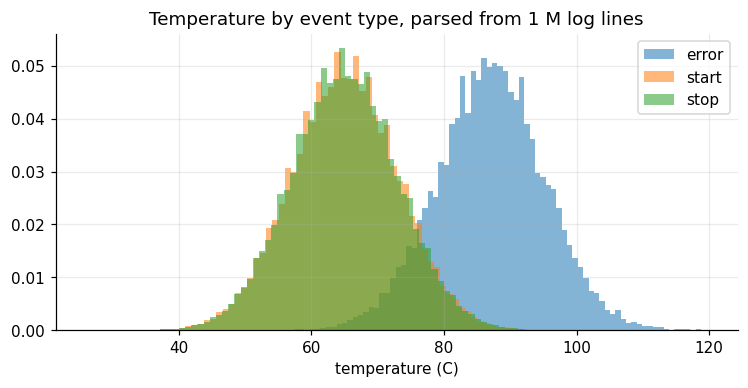

In [8]:
N_LOG = 1_000_000
sub = df.iloc[:N_LOG]
m_ids, t_ids, ev_names = sub.machine.values.tolist(), sub.t.values.tolist(), sub.event.astype(str).values.tolist()
temp = rng.normal(65, 8, N_LOG) + 22 * (sub.event.values == "error")
t0 = time.time()
lines = [f"ts={1791676800 + t} machine=M{m:04d} event={e} temp={x:.1f}"
         for m, t, e, x in zip(m_ids, t_ids, ev_names, temp.tolist())]
bad_idx = rng.choice(N_LOG, N_LOG // 50, replace=False)
for i in bad_idx.tolist():
    l = lines[i]
    lines[i] = l[: len(l) // 2] if i % 2 else l.replace("event=", "evnt=")
print(f"built {len(lines):,} lines in {time.time()-t0:.1f}s;  example: {lines[0]}")

LOG_RE = re.compile(r"^ts=(\d+) machine=(M\d{4}) event=([a-z_]+) temp=(-?\d+\.\d)$")
t0 = time.time()
parsed = [LOG_RE.match(l) for l in lines]
good = [p.groups() for p in parsed if p]
dt = time.time() - t0
print(f"regex parsed {len(lines):,} lines in {dt:.2f}s  ({len(lines)/dt/1e6:.2f} M lines/s); rejected = {len(lines)-len(good):,} ({1-len(good)/len(lines):.2%})")

logs = pd.DataFrame(good, columns=["ts", "machine", "event", "temp"]).astype({"ts": "int64", "temp": "float32"})
by_ev = logs.groupby("event").temp.agg(["count", "mean", "std", "max"]).round(2)
display(by_ev)
hot = logs[logs.temp > 95]
print(f"critical-temperature lines (>95 C): {len(hot):,};  share that are 'error' events: {(hot.event=='error').mean():.1%}")
display(hot.machine.value_counts().head(5).to_frame("hot_events"))
fig, ax = plt.subplots(figsize=(8, 3.5))
for name, g in logs.groupby("event"):
    if name in ("error", "start", "stop"): ax.hist(g.temp, bins=80, alpha=.55, label=name, density=True)
ax.set_xlabel("temperature (C)"); ax.set_title("Temperature by event type, parsed from 1 M log lines"); ax.legend(); plt.show()
results["Log lines parsed by regex"] = f"{len(good):,} / {len(lines):,}"

### Catastrophic backtracking vs. a true DFA
Python's `re` is a *backtracking NFA simulator*, so nested quantifiers like `(a+)+$` take **exponential** time on adversarial input (ReDoS, a real denial-of-service vector that has hit Cloudflare, Stack Overflow and many web apps). A DFA (as used by RE2, Rust's `regex`, Hyperscan) is **linear** by construction.

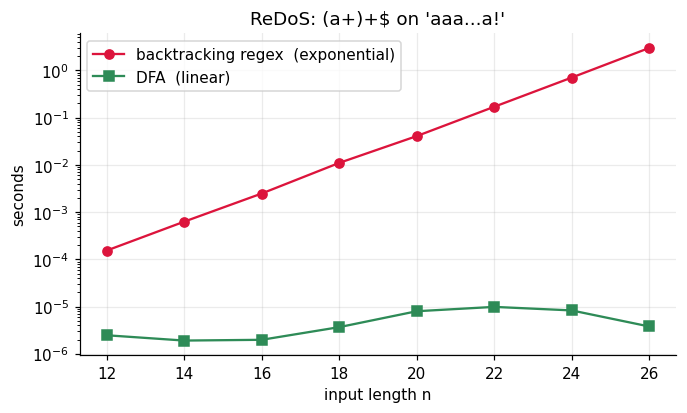

at n=26: regex 2.993s vs DFA 3.8 microseconds


In [9]:
evil = re.compile(r"^(a+)+$")
def dfa_aplus(s):                         # 3-state DFA for the same language a+
    q = 0
    for ch in s:
        if q == 2: break
        q = 1 if ch == "a" else 2
    return q == 1

ns, t_re, t_dfa = [], [], []
for n in range(12, 27, 2):
    s = "a" * n + "!"
    t0 = time.perf_counter(); r1 = evil.match(s); a = time.perf_counter() - t0
    t0 = time.perf_counter(); r2 = dfa_aplus(s);  b = time.perf_counter() - t0
    ns.append(n); t_re.append(a); t_dfa.append(b)
    if a > 4: break
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.semilogy(ns, t_re, "o-", color="crimson", label="backtracking regex  (exponential)")
ax.semilogy(ns, t_dfa, "s-", color="seagreen", label="DFA  (linear)")
ax.set_xlabel("input length n"); ax.set_ylabel("seconds"); ax.legend(); ax.set_title("ReDoS: (a+)+$ on 'aaa...a!'")
plt.show()
results["ReDoS slowdown at n=%d" % ns[-1]] = f"{t_re[-1]/max(t_dfa[-1],1e-9):,.0f}x slower than DFA"
print(f"at n={ns[-1]}: regex {t_re[-1]:.3f}s vs DFA {t_dfa[-1]*1e6:.1f} microseconds")

### Throughput benchmark: table-driven DFA (the PLC/FPGA way)
The same DFA from §1 evaluated three ways on all **2,000,000 events**: a naïve Python `dict` lookup loop, a Python list-of-lists table, and a **vectorised NumPy transition table** that advances all 2,000 machines in lock-step.

,seconds,events/sec (M)
python dict lookups,0.433,4.62
python table lookups,0.234,8.55
numpy vectorised table,0.043,46.75


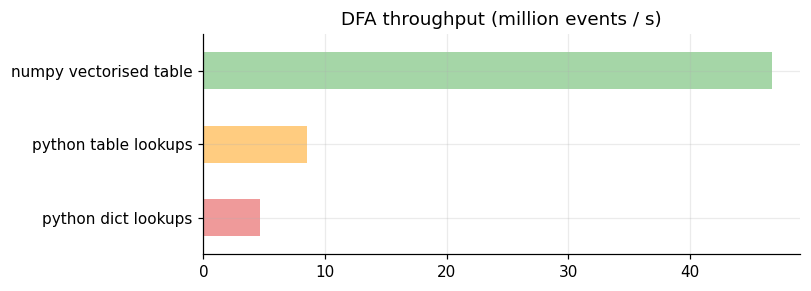

In [10]:
ev_list = ev.tolist(); start_i = S["IDLE"]
t0 = time.time()
for row in ev_list:
    q = machine.start
    for e in row:
        q2 = delta.get((q, EVENTS[e]))
        if q2 is not None: q = q2
t_dict = time.time() - t0

Tl = Tab.tolist()
t0 = time.time()
for row in ev_list:
    q = start_i
    for e in row:
        n_ = Tl[q][e]
        if n_ != DEAD: q = n_
t_list = time.time() - t0

t0 = time.time(); _ = monitor(ev, Tab, DEAD, start_i); t_vec = time.time() - t0
bench = pd.DataFrame({"seconds": [t_dict, t_list, t_vec]}, index=["python dict lookups", "python table lookups", "numpy vectorised table"])
bench["events/sec (M)"] = (ev.size / bench.seconds / 1e6).round(2)
display(bench.round(3))
bench["events/sec (M)"].plot.barh(color=["#ef9a9a", "#ffcc80", "#a5d6a7"], figsize=(7, 2.6), title="DFA throughput (million events / s)")
plt.show()
results["Fastest DFA throughput"] = f"{bench['events/sec (M)'].max():.1f} M events/s"

## 4. DFA minimisation: removing redundancy from generated controllers

Auto-generated controllers (from model checkers, product constructions, UML tools) contain **equivalent states**. Moore's partition-refinement algorithm merges them, shrinking silicon area, memory and verification cost.

Example: an error-counter that fires a "lock-out" when *errors ≡ 0 (mod 4)*, but was generated by naively counting mod 12, plus unreachable states.

In [11]:
def minimize(dfa):
    # 1) drop unreachable states  2) Moore partition refinement
    reach, stack = {dfa.start}, [dfa.start]
    while stack:
        q = stack.pop()
        for a in dfa.alphabet:
            r = dfa.delta.get((q, a))
            if r is not None and r not in reach: reach.add(r); stack.append(r)
    Q = [q for q in dfa.states if q in reach]
    part = {q: int(q in dfa.accepting) for q in Q}
    while True:
        sig = {q: (part[q], tuple(part.get(dfa.delta.get((q, a))) for a in dfa.alphabet)) for q in Q}
        ids = {s: i for i, s in enumerate(sorted(set(sig.values()), key=str))}
        new = {q: ids[sig[q]] for q in Q}
        if len(set(new.values())) == len(set(part.values())): break
        part = new
    part = new
    nd_ = {(part[q], a): part[dfa.delta[(q, a)]] for q in Q for a in dfa.alphabet if (q, a) in dfa.delta}
    return DFA(sorted(set(part.values())), dfa.alphabet, nd_, part[dfa.start], {part[q] for q in Q if q in dfa.accepting}), len(Q)

# redundant "count errors mod 12" controller + 8 unreachable orphan states
big = {(i, "e"): (i + 1) % 12 for i in range(12)}; big.update({(i, "o"): i for i in range(12)})
for j in range(100, 108): big[(j, "e")] = (j + 1) % 12; big[(j, "o")] = j
redundant = DFA(list(range(12)) + list(range(100, 108)), ["e", "o"], big, 0, {i for i in range(12) if i % 4 == 0})
small, reachable = minimize(redundant)
print(f"states: {len(redundant.states)} generated -> {reachable} reachable -> {len(small.states)} minimal")
tests = [[random.choice("eo") for _ in range(random.randint(0, 60))] for _ in range(20000)]
print("language preserved on 20,000 random words:", all(redundant.accepts(w) == small.accepts(w) for w in tests))
results["DFA minimisation"] = f"{len(redundant.states)} → {len(small.states)} states"

states: 20 generated -> 12 reachable -> 4 minimal


language preserved on 20,000 random words: True


## 5. Pushdown Automaton (PDA): nested workflow blocks

Anything with **nesting** (JSON/XML, BPMN workflows, PLC `IF…END_IF`, Kubernetes manifests, smart-contract bytecode, parentheses in an AI-agent tool-call) is *context-free* and **cannot be recognised by any finite automaton**. A PDA adds a **stack**.

We validate **100,000** generated workflow programs (`( )` sequence, `[ ]` parallel, `{ }` loop) of which 30 % are corrupted, and cross-check the PDA against an independent oracle.

In [12]:
OPEN, CLOSE = "([{", ")]}"
def gen_valid(r):
    left, out, stack = r.randint(3, 25), [], []
    while left or stack:
        if left and (not stack or r.random() < .55):
            o = r.choice(OPEN); out.append(o); stack.append(o); left -= 1
        else:
            out.append(CLOSE[OPEN.index(stack.pop())])
    return "".join(out)

def corrupt(s, r):
    k, i = r.random(), r.randrange(len(s))
    if k < .35: return s[:i] + s[i + 1:]                       # dropped token
    if k < .70: return s[:i] + r.choice(OPEN + CLOSE) + s[i + 1:]  # flipped token
    return s[:i]                                                # truncated stream

def pda(s):
    # states: q_run -> accept iff stack empty at end;  push on opener, pop on matching closer
    stack, maxd = [], 0
    for ch in s:
        if ch in OPEN:
            stack.append(ch)
            if len(stack) > maxd: maxd = len(stack)
        else:
            if not stack: return "UNDERFLOW", maxd
            if stack.pop() != OPEN[CLOSE.index(ch)]: return "MISMATCH", maxd
    return ("OK" if not stack else "UNCLOSED"), maxd

def oracle(s):                      # independent reference: repeatedly cancel adjacent pairs
    while True:
        t = s.replace("()", "").replace("[]", "").replace("{}", "")
        if t == s: return s == ""
        s = t

r = random.Random(7); N_PROG = 100_000
progs, intended = [], []
for _ in range(N_PROG):
    s = gen_valid(r)
    if r.random() < .30: s, flag = corrupt(s, r), False
    else: flag = True
    progs.append(s); intended.append(flag)
tokens = sum(map(len, progs)); print(f"{N_PROG:,} programs, {tokens:,} tokens")

t0 = time.time(); res = [pda(s) for s in progs]; dt = time.time() - t0
status = pd.Series([x[0] for x in res]); depth = np.array([x[1] for x in res])
print(f"PDA validated {tokens:,} tokens in {dt:.2f}s ({tokens/dt/1e6:.2f} M tokens/s)")
display(pd.crosstab(pd.Series(intended, name="intended valid"), status.rename("PDA verdict")))
agree = np.mean([(status[i] == "OK") == oracle(progs[i]) for i in range(0, N_PROG, 5)])
print(f"agreement with independent oracle on 20,000 programs: {agree:.2%}")
print(f"valid programs accepted: {(status[np.array(intended)]=='OK').mean():.2%}")
results["PDA programs validated"] = f"{N_PROG:,} ({tokens:,} tokens)"

100,000 programs, 2,660,747 tokens


PDA validated 2,660,747 tokens in 0.37s (7.19 M tokens/s)


PDA verdict,MISMATCH,OK,UNCLOSED,UNDERFLOW
intended valid,,,,
False,13302,2985,10771,2917
True,0,70025,0,0


agreement with independent oracle on 20,000 programs: 100.00%
valid programs accepted: 100.00%


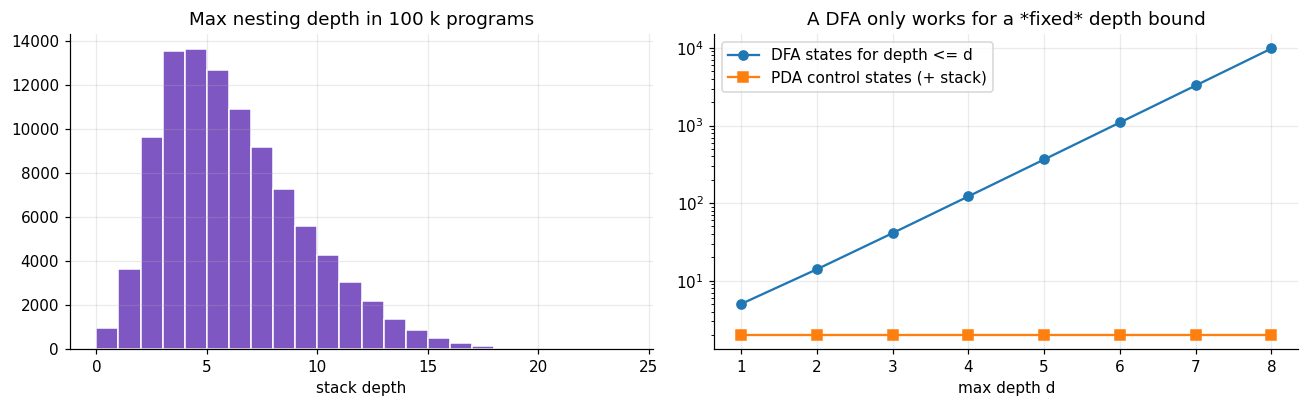

deepest program needs depth 23 -> a DFA would need 141,214,768,241 states


In [13]:
# Why a DFA is not enough: a DFA must remember the *whole stack contents* up to a depth bound
depths = np.arange(1, 9)
dfa_needed = [(3 ** (d + 1) - 1) // 2 + 1 for d in depths]          # all bracket strings of length <= d, plus dead state
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].hist(depth, bins=range(0, depth.max() + 2), color="#7e57c2", edgecolor="w")
ax[0].set_title("Max nesting depth in 100 k programs"); ax[0].set_xlabel("stack depth")
ax[1].semilogy(depths, dfa_needed, "o-", label="DFA states for depth <= d"); ax[1].semilogy(depths, [2] * len(depths), "s-", label="PDA control states (+ stack)")
ax[1].set_xlabel("max depth d"); ax[1].legend(); ax[1].set_title("A DFA only works for a *fixed* depth bound")
plt.tight_layout(); plt.show()
print(f"deepest program needs depth {depth.max()} -> a DFA would need {(3**(depth.max()+1)-1)//2+1:,} states")

## 6. Turing Machine: verifying production-line balance (aⁿbⁿcⁿ)

A line produces **a**ssembled units, **b**oxed units and **c**rated units. A batch is correct iff all three counts are *equal and in order*: **aⁿbⁿcⁿ**. This language is **not context-free**, so no PDA can verify it. A Turing machine can (tape = unlimited memory). We run a real TM on 3,000 batches and measure its **O(n²)** cost.

'aabbcc'       -> (True, 23)
'aabbc'        -> (False, 13)
'abcabc'       -> (False, 7)
'aaabbbccc'    -> (True, 46)
''             -> (False, 0)
'cba'          -> (False, 0)


TM verdict == ground truth on 3,000 batches: 100.00%  (1.2s, 4,431,518 TM steps)


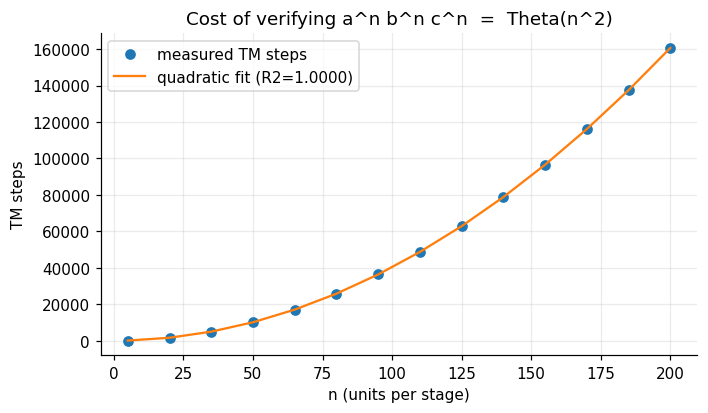

In [14]:
class TuringMachine:
    def __init__(self, delta, start, accept, blank="_"):
        self.delta, self.start, self.accept, self.blank = delta, start, accept, blank
    def run(self, word, max_steps=10**8):
        tape, q, head, steps = list(word) or [self.blank], self.start, 0, 0
        while q != self.accept and steps < max_steps:
            if head >= len(tape): tape.append(self.blank)
            key = (q, tape[head])
            if key not in self.delta: return False, steps          # halt & reject
            q, w, mv = self.delta[key]
            tape[head] = w; head += 1 if mv == "R" else -1; steps += 1
            if head < 0: tape.insert(0, self.blank); head = 0
        return q == self.accept, steps

d = {("q0", "a"): ("q1", "X", "R"), ("q0", "Y"): ("q4", "Y", "R"),                       # mark an a, or finish
     ("q1", "a"): ("q1", "a", "R"), ("q1", "Y"): ("q1", "Y", "R"), ("q1", "b"): ("q2", "Y", "R"),
     ("q2", "b"): ("q2", "b", "R"), ("q2", "Z"): ("q2", "Z", "R"), ("q2", "c"): ("q3", "Z", "L"),
     ("q3", "X"): ("q0", "X", "R"),
     ("q4", "Y"): ("q4", "Y", "R"), ("q4", "Z"): ("q4", "Z", "R"), ("q4", "_"): ("qa", "_", "R")}
for s_ in "abYZ": d[("q3", s_)] = ("q3", s_, "L")
tm = TuringMachine(d, "q0", "qa")

for w in ["aabbcc", "aabbc", "abcabc", "aaabbbccc", "", "cba"]:
    print(f"{w!r:14} -> {tm.run(w)}")

def truth(s):
    m = re.fullmatch(r"(a+)(b+)(c+)", s)
    return bool(m) and len(m.group(1)) == len(m.group(2)) == len(m.group(3))

r = random.Random(11); batches = []
for _ in range(3000):
    n = r.randint(1, 40); k = r.random()
    if k < .5:  s = "a" * n + "b" * n + "c" * n
    elif k < .8: s = "a" * n + "b" * r.randint(1, 40) + "c" * r.randint(1, 40)
    else:        s = "".join(r.sample("a" * n + "b" * n + "c" * n, 3 * n))
    batches.append(s)
t0 = time.time(); out = [tm.run(s) for s in batches]
acc = np.mean([o[0] == truth(s) for o, s in zip(out, batches)])
print(f"TM verdict == ground truth on {len(batches):,} batches: {acc:.2%}  ({time.time()-t0:.1f}s, {sum(o[1] for o in out):,} TM steps)")

ns = np.arange(5, 205, 15); steps = np.array([tm.run("a" * n + "b" * n + "c" * n)[1] for n in ns])
coef = np.polyfit(ns, steps, 2); r2 = 1 - ((steps - np.polyval(coef, ns)) ** 2).sum() / ((steps - steps.mean()) ** 2).sum()
fig, ax = plt.subplots(figsize=(7, 3.8)); ax.plot(ns, steps, "o", label="measured TM steps"); ax.plot(ns, np.polyval(coef, ns), "-", label=f"quadratic fit (R2={r2:.4f})")
ax.set_xlabel("n (units per stage)"); ax.set_ylabel("TM steps"); ax.legend(); ax.set_title("Cost of verifying a^n b^n c^n  =  Theta(n^2)"); plt.show()
results["Turing machine accuracy"] = f"{acc:.1%} on {len(batches):,} batches (O(n²) verified, R²={r2:.4f})"

## 7. Probabilistic automaton: predictive maintenance

Replace "is there a transition?" with "**with what probability?**". A DFA whose edges carry probabilities is a **Markov chain / probabilistic automaton**. We *learn* it from the 2 M recorded transitions, then use linear algebra to **predict** failures, which is the basis of condition-based maintenance.

,OFF,IDLE,RUNNING,FAULT,MAINT
OFF,0.026,0.974,0.000,0.000,0.000
IDLE,0.115,0.017,0.776,0.000,0.093
RUNNING,0.000,0.938,0.021,0.041,0.000
FAULT,0.083,0.781,0.000,0.017,0.119
MAINT,0.101,0.878,0.000,0.000,0.021


,stationary (theory),observed (2 M events)
OFF,0.0636,0.0636
IDLE,0.4867,0.4864
RUNNING,0.3857,0.3859
FAULT,0.0160,0.0160
MAINT,0.0480,0.0480


max |theory - observed| = 0.00025
MTBF (events between failures): predicted 63.5 | observed 63.5


,expected events to next FAULT
OFF,63.2
IDLE,62.2
RUNNING,60.6
MAINT,63.3


Monte-Carlo (200,000 chains) from IDLE: 62.3 vs analytic 62.2


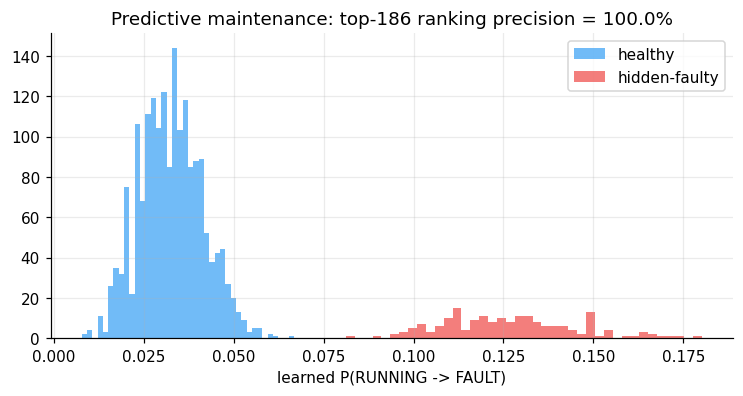

In [15]:
P = cnt / cnt.sum(1, keepdims=True)
display(pd.DataFrame(P, index=STATES, columns=STATES).round(3))

# stationary distribution:  pi P = pi
w_, v_ = np.linalg.eig(P.T); pi = np.real(v_[:, np.argmin(abs(w_ - 1))]); pi /= pi.sum()
emp = np.bincount(after.ravel(), minlength=5) / after.size
display(pd.DataFrame({"stationary (theory)": pi, "observed (2 M events)": emp}, index=STATES).round(4))
print("max |theory - observed| =", np.abs(pi - emp).max().round(5))

# mean time between failures: entry rate into FAULT
rate = sum(pi[s] * P[s, S["FAULT"]] for s in range(5) if s != S["FAULT"])
mtbf_pred = 1 / rate; mtbf_obs = ev.size / fault_entries.sum()
print(f"MTBF (events between failures): predicted {mtbf_pred:.1f} | observed {mtbf_obs:.1f}")

# expected number of events until FAULT from each state (absorbing chain):  h = (I - Q)^-1 1
keep = [s for s in range(5) if s != S["FAULT"]]; Q = P[np.ix_(keep, keep)]
h = np.linalg.solve(np.eye(4) - Q, np.ones(4))
display(pd.Series(h, index=[STATES[s] for s in keep], name="expected events to next FAULT").round(1).to_frame())

# Monte-Carlo check of h(IDLE) with 200,000 simulated chains
n_mc = 200_000; cur = np.full(n_mc, S["IDLE"]); alive = np.ones(n_mc, bool); life = np.zeros(n_mc); cumP = P.cumsum(1)
while alive.any():
    life[alive] += 1
    nxt = np.minimum((rng.random((n_mc, 1)) > cumP[cur]).sum(1), 4)
    cur = np.where(alive, nxt, cur); alive &= cur != S["FAULT"]
print(f"Monte-Carlo (200,000 chains) from IDLE: {life.mean():.1f} vs analytic {h[keep.index(S['IDLE'])]:.1f}")

# rank machines by learned P(RUNNING -> FAULT)
run_steps = (before == S["RUNNING"]).sum(1); to_fault = ((before == S["RUNNING"]) & (after == S["FAULT"])).sum(1)
p_fault = to_fault / np.maximum(run_steps, 1)
top = np.argsort(-p_fault)[:faulty.sum()]
prec = faulty[top].mean()
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(p_fault[~faulty], bins=40, alpha=.75, label="healthy", color="#42a5f5"); ax.hist(p_fault[faulty], bins=40, alpha=.75, label="hidden-faulty", color="#ef5350")
ax.set_xlabel("learned P(RUNNING -> FAULT)"); ax.legend(); ax.set_title(f"Predictive maintenance: top-{len(top)} ranking precision = {prec:.1%}"); plt.show()
results["Predictive-maintenance precision"] = f"{prec:.1%} of truly faulty machines found in top {len(top)}"
results["MTBF predicted vs observed"] = f"{mtbf_pred:.1f} vs {mtbf_obs:.1f} events"

## 8. DFA as a business-process monitor: 1 M e-commerce orders (RPA / workflow automation)

Order-to-delivery pipelines, loan approvals, insurance claims and CI/CD runs are all DFAs with *accepting* end-states. Run as a **conformance checker**, the automaton flags orders that break the process (payment skipped, shipped-before-packed, bot/fraud activity) in real time. Here: **1,000,000 orders × 12 events**.

simulated + monitored 12,000,000 order-events in 1.0s


,orders,completed (accepted),completion rate
all,1000000,896811,89.7%
with >=1 violation,146383,128197,87.6%
clean,853617,768614,90.0%


stuck / in-flight orders after 12 events: 103,189 (10.3%)  -> candidates for SLA escalation by the automaton
orders that received an illegal event (rejected by the DFA) yet still completed: 128,197


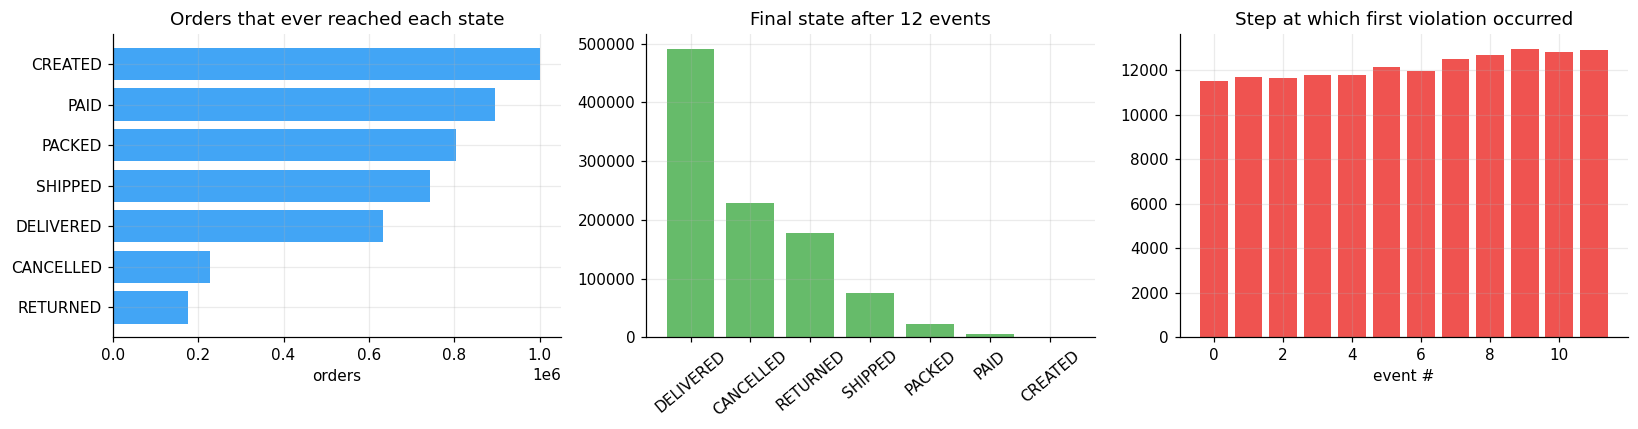

violations,0,1,2,3,4
orders,853617,136251,9731,384,17


In [16]:
O_ST = ["CREATED", "PAID", "PACKED", "SHIPPED", "DELIVERED", "CANCELLED", "RETURNED"]
O_EV = ["pay", "pack", "ship", "deliver", "cancel", "return", "noop"]
od = {("CREATED", "pay"): "PAID", ("CREATED", "cancel"): "CANCELLED",
      ("PAID", "pack"): "PACKED", ("PAID", "cancel"): "CANCELLED",
      ("PACKED", "ship"): "SHIPPED", ("PACKED", "cancel"): "CANCELLED",
      ("SHIPPED", "deliver"): "DELIVERED", ("SHIPPED", "return"): "RETURNED",
      ("DELIVERED", "return"): "RETURNED"}
for s_ in O_ST: od[(s_, "noop")] = s_
order_dfa = DFA(O_ST, O_EV, od, "CREATED", {"DELIVERED", "CANCELLED", "RETURNED"})
OT, ODEAD = order_dfa.table()
OS = {s: i for i, s in enumerate(O_ST)}; OE = {e: i for i, e in enumerate(O_EV)}

W = np.zeros((7, 7), np.float32)
W[OS["CREATED"],   [OE["pay"], OE["cancel"], OE["noop"]]]    = [.45, .05, .50]
W[OS["PAID"],      [OE["pack"], OE["cancel"], OE["noop"]]]   = [.40, .04, .56]
W[OS["PACKED"],    [OE["ship"], OE["cancel"], OE["noop"]]]   = [.45, .02, .53]
W[OS["SHIPPED"],  [OE["deliver"], OE["return"], OE["noop"]]] = [.40, .02, .58]
W[OS["DELIVERED"], [OE["return"], OE["noop"]]]               = [.06, .94]
W[OS["CANCELLED"], OE["noop"]] = 1; W[OS["RETURNED"], OE["noop"]] = 1
Wc = W.cumsum(1)

N_ORD, N_STEP, NOISE = 1_000_000, 12, 0.02
t0 = time.time()
cur = np.zeros(N_ORD, np.int16); visited = np.zeros((N_ORD, 7), bool); visited[:, 0] = True
n_viol = np.zeros(N_ORD, np.int8); first_viol_step = np.full(N_ORD, -1, np.int8)
for step in range(N_STEP):
    e = np.minimum((rng.random((N_ORD, 1), dtype=np.float32) > Wc[cur]).sum(1), 6)
    e = np.where(rng.random(N_ORD) < NOISE, rng.integers(0, 7, N_ORD), e)       # rogue / buggy events
    nxt = OT[cur, e]; bad = nxt == ODEAD
    first_viol_step = np.where(bad & (first_viol_step < 0), step, first_viol_step)
    n_viol += bad; cur = np.where(bad, cur, nxt)
    visited[np.arange(N_ORD), cur] = True
print(f"simulated + monitored {N_ORD*N_STEP:,} order-events in {time.time()-t0:.1f}s")

final = pd.Series(np.array(O_ST)[cur]).value_counts()
accepted = np.isin(cur, [OS["DELIVERED"], OS["CANCELLED"], OS["RETURNED"]])
has_v = n_viol > 0
tbl = pd.DataFrame({"orders": [N_ORD, has_v.sum(), (~has_v).sum()],
                    "completed (accepted)": [accepted.sum(), accepted[has_v].sum(), accepted[~has_v].sum()]},
                   index=["all", "with >=1 violation", "clean"])
tbl["completion rate"] = (tbl["completed (accepted)"] / tbl["orders"]).map("{:.1%}".format)
display(tbl)
stuck = ~accepted
print(f"stuck / in-flight orders after {N_STEP} events: {stuck.sum():,} ({stuck.mean():.1%})  -> candidates for SLA escalation by the automaton")
print(f"orders that received an illegal event (rejected by the DFA) yet still completed: {(has_v & accepted).sum():,}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
funnel = visited.sum(0)
ax[0].barh(O_ST[::-1], funnel[::-1], color="#42a5f5"); ax[0].set_title("Orders that ever reached each state"); ax[0].set_xlabel("orders")
ax[1].bar(final.index, final.values, color="#66bb6a"); ax[1].set_title("Final state after 12 events"); ax[1].tick_params(axis="x", rotation=40)
vs = pd.Series(first_viol_step[first_viol_step >= 0]).value_counts().sort_index()
ax[2].bar(vs.index, vs.values, color="#ef5350"); ax[2].set_title("Step at which first violation occurred"); ax[2].set_xlabel("event #")
plt.tight_layout(); plt.show()

sus = pd.DataFrame({"violations": n_viol}).value_counts().sort_index().rename("orders").to_frame()
display(sus.T)
results["Orders audited by DFA"] = f"{N_ORD:,} ({N_ORD*N_STEP:,} events)"
results["Orders flagged non-conformant"] = f"{has_v.sum():,} ({has_v.mean():.1%})"
results["Orders completed (accepting state)"] = f"{accepted.mean():.1%}"
results["Orders stuck / in-flight"] = f"{stuck.sum():,} ({stuck.mean():.1%})"

## 9. Scorecard and take-aways

In [17]:
score = pd.Series(results, name="result").to_frame()
display(score)
total_events = len(df) + N_LOG + tokens + N_ORD * N_STEP
print(f"\nTotal symbols processed by automata in this notebook: {total_events:,}")

,result
Events processed by DFA,"2,000,000"
Protocol violations flagged,"39,131 (1.96%)"
Alarms raised by Mealy machine,"31,504"
Infant-mortality patterns found,"3,960"
Worst-case NFA→DFA blow-up (k=12),"13 → 4,096 states"
Log lines parsed by regex,"980,000 / 1,000,000"
ReDoS slowdown at n=26,"789,749x slower than DFA"
Fastest DFA throughput,46.8 M events/s
DFA minimisation,20 → 4 states
PDA programs validated,"100,000 (2,660,747 tokens)"



Total symbols processed by automata in this notebook: 17,660,747


| Automaton | Memory | Recognises | Typical modern use | Key lesson from the data above |
|-----------|--------|-----------|--------------------|-------------------------------|
| **DFA / Mealy / Moore** | finite state | regular | PLCs, IoT lifecycles, protocol checkers, workflow monitors | Table-driven evaluation reaches **tens of millions of events/s**; violations = anomalies |
| **NFA** | finite, non-deterministic | regular | pattern matching, IDS signatures | Convenient to *write*, but determinising can cost **2ᵏ** states |
| **Regex engines** | finite | regular | log parsing, WAF, input validation | Backtracking engines are exploitable (**ReDoS**); DFA-based engines are linear |
| **Minimisation** | n/a | n/a | model-checking, hardware synthesis | Generated controllers shrink drastically with identical behaviour |
| **PDA** | one stack | context-free | JSON/XML/BPMN/source-code validation | Nesting is impossible for a finite automaton at unbounded depth |
| **Turing machine** | unbounded tape | decidable / r.e. | general computation, verification limits | Even simple cross-checks (aⁿbⁿcⁿ) cost Θ(n²) |
| **Probabilistic automaton** | finite + probabilities | stochastic behaviour | predictive maintenance, reliability, RL environments | Learned from logs, it predicted MTBF and found the hidden faulty machines |

**Where to go next:** timed automata (UPPAAL) for real-time systems, Büchi automata for LTL model checking of safety properties, learned automata (L*, RNN → DFA extraction) for auditing ML-driven controllers, and neural/AI-agent guardrails expressed as finite-state policies.